# Data-Driven Analysis of Hospital Operations and Resource Utilization Using Python

## Project Name:

Hospital Operations Analysis.

Dataset : 5075 rows and 22 column

 ## Project Overview:

 Healthcare institutions generate large volumes of operational data related to patient admission, treatments, resource utilization, and departmental performance.Analyzing this data helps hospitals improve efficiency, optimize resouce allocation, and enhance patient care.

## Problem statement:

Hospital generate large volumes of operational data daily. Without proper analysis,it becomes difficult to optimize resource, manage patient flow, and improve healthcare service. This project uses data analytics techniques to uncover trends and support data-driven decision-making.


## Project Objective:

The objective of this to analyze hospital operational data to identify patterns in patient admissions, treatment outcomes, resources utilization, length of stay, and departmental performance.
The analysis aims to provide actinable insights that support efficient hospital management and improved patient care.

Specific objectives include:

-Understanding patient admission trends.
-Analyzing disease severity levels.
-Evaluating ICU requirement.
-Identifying factors affecting length of stay.
-Examining hospital resorce utilization.
-Providing recommendations for operational improvement.

## Import Liabraries

In [3]:
import pandas as pd
import numpy as np

## Load Dataset

In [4]:
df=pd.read_csv(r"C:\Users\umair\Downloads\Hospital operations.zip")
df.head()

,Patient_ID,Visit_Date,Age,Gender,Disease,Severity,Admission_Type,Length_of_Stay,Bed_Required,ICU_Required,...,Total_Beds_Available,Beds_Occupied,ICU_Beds_Available,ICU_Beds_Occupied,Oxygen_Units_Used,Month,Season,Day_of_Week,Department,Readmission_Within_30_Days
0,P00624,2023-03-21,63,Male,Food Poisoning,Mild,OPD,0.0,No,No,...,247,156,19,9,3.0,3,Spring,Tuesday,Gastroenterology,No
1,P02862,2023-03-04,44,Male,Liver Disease,Severe,Emergency,9.0,No,No,...,145,92,28,13,4.0,3,Spring,Saturday,Gastroenterology,No
2,P01271,2024-11-10,52,Female,Anemia,Moderate,Inpatient,2.0,Yes,No,...,105,62,20,9,1.0,11,Autumn,Sunday,General Medicine,Yes
3,P02681,2023-02-27,63,Male,Thyroid Disorder,Moderate,OPD,0.0,No,No,...,203,136,21,13,1.0,2,Winter,Monday,General Medicine,No
4,P04980,2023-07-09,72,Male,Heart Disease,Severe,Emergency,11.0,Yes,Yes,...,194,118,31,12,2.0,7,Monsoon,Sunday,ICU,No


### Dataset Understanding.

In [26]:
print("Dataset Shape",df.shape)

Dataset Shape (5075, 22)


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5075 entries, 0 to 5074
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   Patient_ID                  5075 non-null   object  
 1   Visit_Date                  5075 non-null   object  
 2   Age                         5075 non-null   int64   
 3   Gender                      4972 non-null   object  
 4   Disease                     5075 non-null   object  
 5   Severity                    5075 non-null   object  
 6   Admission_Type              5075 non-null   object  
 7   Length_of_Stay              5025 non-null   float64 
 8   Bed_Required                5075 non-null   object  
 9   ICU_Required                5075 non-null   object  
 10  Oxygen_Required             5075 non-null   object  
 11  Ventilator_Required         5075 non-null   object  
 12  Total_Beds_Available        5075 non-null   int64   
 13  Beds_Occupied     

## Missing Values Analysis

In [83]:
# check missing values
df.isnull().sum()

Patient_ID                      0
Visit_Date                      0
Age                             0
Gender                        103
Disease                         0
Severity                        0
Admission_Type                  0
Length_of_Stay                 50
Bed_Required                    0
ICU_Required                    0
Oxygen_Required                 0
Ventilator_Required             0
Total_Beds_Available            0
Beds_Occupied                   0
ICU_Beds_Available              0
ICU_Beds_Occupied               0
Oxygen_Units_Used             100
Month                           0
Season                          0
Day_of_Week                     0
Department                     77
Readmission_Within_30_Days      0
dtype: int64

## Missing values Analysis 

The dataset was examinined for missing values to assess data quality and completeness.

Four columns were found to contain missing values:

-Gender: 103 missing values.

-Length of stay : 50 missing values.

-Oxygen units used : 100 missing values.

-Department : 77 missing values.

Appropriate imputation techniques will be applied to handle these missing values and ensure the dataset is suitable for further analysis.

## Handling Missing Values

### 1. Gender Column

In [5]:
df["Gender"]=df["Gender"].fillna("Other")
print("Missing Values in Gender : ",df['Gender'].isnull().sum())

Missing Values in Gender :  0


### Observation

The 103 missing values in the `Gender column` were successfully replaced with "Other". No missing values remain in this column.

### 2 . Length of Stay

In [6]:
Median=df["Length_of_Stay"].median()
df["Length_of_Stay"]=df["Length_of_Stay"].fillna(Median)
print('Missing Values in Length_of_Stay :',df['Length_of_Stay'].isnull().sum())

Missing Values in Length_of_Stay : 0


### Observation

The `Length_of_Stay` column contained 50 missing values. Since it is a numerical variable, the missing values were replaced using the median value. The median was selected because it is less affected by extreme values or outliers. After treatment, no missing values remain in this column.

### 3 . Oxygen Unit Used

In [7]:
Median=df["Oxygen_Units_Used"].median()
df["Oxygen_Units_Used"]=df["Oxygen_Units_Used"].fillna(Median)
print("Missing Values in Oxygen_Unit_Used : ",df['Oxygen_Units_Used'].isnull().sum())

Missing Values in Oxygen_Unit_Used :  0


### Observation

The `Oxygen_Units_Used` column contained 100 missing values. Since it is a numerical variable, the missing values were replaced using the median value. The median was selected because it is less affected by extreme values or outliers. After treatment, no missing values remain in this column.

### 4 . Department

In [8]:
df["Department"]=df["Department"].fillna("Unknown")
print("The Missing Values in Department : ",df['Department'].isnull().sum())

The Missing Values in Department :  0


### Observation

The `Department` column contained 77 missing values. Since it is a categorical variable, the missing values were replaced with "Unknown" to preserve the records and indicate that the department information was unavailable. After treatment, no missing values remain in this column.

In [9]:
df.columns

Index(['Patient_ID', 'Visit_Date', 'Age', 'Gender', 'Disease', 'Severity',
       'Admission_Type', 'Length_of_Stay', 'Bed_Required', 'ICU_Required',
       'Oxygen_Required', 'Ventilator_Required', 'Total_Beds_Available',
       'Beds_Occupied', 'ICU_Beds_Available', 'ICU_Beds_Occupied',
       'Oxygen_Units_Used', 'Month', 'Season', 'Day_of_Week', 'Department',
       'Readmission_Within_30_Days'],
      dtype='object')

I checked the dataset for unwanted or irrelavent columns. All the available columns are relavent to hospital operations analysis, so no columns were removed.

## Handling Duplicate values

In [53]:
#Number of duplicate values
df.duplicated().sum()

np.int64(75)

There are 75 duplicate rows in the dataset

In [9]:
#Remove duplicate rows
df=df.drop_duplicates()

In [55]:
df.duplicated().sum()

np.int64(0)

The duplicate rows were remove with drop_duplicates().After removal, the dataset was verified again, and the duplicate count was 0.

## Check incorrect datatypes


In [48]:
df.dtypes

Patient_ID                     object
Visit_Date                     object
Age                             int64
Gender                         object
Disease                        object
Severity                       object
Admission_Type                 object
Length_of_Stay                float64
Bed_Required                   object
ICU_Required                   object
Oxygen_Required                object
Ventilator_Required            object
Total_Beds_Available            int64
Beds_Occupied                   int64
ICU_Beds_Available              int64
ICU_Beds_Occupied               int64
Oxygen_Units_Used             float64
Month                           int64
Season                         object
Day_of_Week                    object
Department                     object
Readmission_Within_30_Days     object
dtype: object

In our dastaset Visit_Date column is object datatype, so we want to convert it to datetime datatype.

In [10]:
df["Visit_Date"]=pd.to_datetime(df["Visit_Date"],format='mixed',dayfirst=True)

In [11]:
df.dtypes

Patient_ID                            object
Visit_Date                    datetime64[ns]
Age                                    int64
Gender                                object
Disease                               object
Severity                              object
Admission_Type                        object
Length_of_Stay                       float64
Bed_Required                          object
ICU_Required                          object
Oxygen_Required                       object
Ventilator_Required                   object
Total_Beds_Available                   int64
Beds_Occupied                          int64
ICU_Beds_Available                     int64
ICU_Beds_Occupied                      int64
Oxygen_Units_Used                    float64
Month                                  int64
Season                                object
Day_of_Week                           object
Department                            object
Readmission_Within_30_Days            object
dtype: obj

## Observation – Data Type Conversion

The "Visit Date" column was initially stored as an "object" data type. Since it represents dates, it was converted to the appropriate "datetime" data type using "pd.to_datetime()". This makes the column suitable for date-based analysis and calculations.

In [12]:
df[["Visit_Date"]]

,Visit_Date
0,2023-03-21
1,2023-03-04
2,2024-11-10
3,2023-02-27
4,2023-07-09
...,...
5070,2023-06-10
5071,2023-05-27
5072,2023-08-17
5073,2024-10-02


(The visit date column was checked for inconsistent date formats. Some dates were stored in different formats, such as YYYY-MM-DD and DD-MM-YYYY. I used dayfirst=True , it tells Pandas to treat the first value in the date as the day.)

## Check inconsistent values

In [13]:
# 1 Age
df["Age"].describe()

count    5000.000000
mean       49.605200
std        22.425046
min         0.000000
25%        32.000000
50%        51.000000
75%        68.000000
max       120.000000
Name: Age, dtype: float64

The Age column is a numerical variable. Descriptive statistics are used to understand the central tendency, spread, and range of patient ages in the dataset.

In [14]:
df[df["Age"]==0]

,Patient_ID,Visit_Date,Age,Gender,Disease,Severity,Admission_Type,Length_of_Stay,Bed_Required,ICU_Required,...,Total_Beds_Available,Beds_Occupied,ICU_Beds_Available,ICU_Beds_Occupied,Oxygen_Units_Used,Month,Season,Day_of_Week,Department,Readmission_Within_30_Days
1733,P01600,2024-01-06,0,Other,Influenza,Mild,OPD,0.0,No,No,...,121,101,22,12,0.0,1,Winter,Saturday,General Medicine,No
1821,P01086,2023-09-03,0,Female,Dengue,Moderate,OPD,0.0,Yes,No,...,116,92,17,9,49.0,9,Monsoon,Sunday,General Medicine,No


Two records were found with an age value of 0. Since an age of 0 can represent a newborn patient, these records were considered potentially valid.

In [15]:
df[df["Age"]==120]

,Patient_ID,Visit_Date,Age,Gender,Disease,Severity,Admission_Type,Length_of_Stay,Bed_Required,ICU_Required,...,Total_Beds_Available,Beds_Occupied,ICU_Beds_Available,ICU_Beds_Occupied,Oxygen_Units_Used,Month,Season,Day_of_Week,Department,Readmission_Within_30_Days
66,P02277,2024-05-27,120,Female,Allergy,Mild,Emergency,3.0,Yes,No,...,154,111,27,14,5.0,5,Summer,Monday,General Medicine,Yes
3458,P02244,2023-09-09,120,Female,Hypertension,Moderate,Emergency,7.0,Yes,No,...,171,123,11,7,2.0,9,Monsoon,Saturday,Cardiology,No
3744,P03037,2024-05-21,120,Male,Gastritis,Mild,OPD,0.0,No,No,...,192,129,27,11,1.0,5,Summer,Tuesday,Gastroenterology,No
4478,P01645,2023-08-29,120,Male,Chronic Kidney Disease,Severe,Inpatient,13.0,Yes,Yes,...,129,95,17,9,0.0,8,Monsoon,Tuesday,ICU,No
4754,P00423,2024-10-13,120,Female,Bronchitis,Mild,OPD,0.0,No,No,...,163,91,23,14,1.0,10,Autumn,Sunday,Pulmonology,No


Five records were identified with an age of 120. Since this value is considered an extreme and inconsistent value in the dataset, it is replaced with the median age of the remaining valid records. The median is used because it is less affected by extreme values than the mean.

In [17]:
median_age=df.loc[df["Age"]!=120,"Age"].median()
df.loc[df["Age"]==120,"Age"]=median_age

In [12]:
df[df["Age"]==120]

,Patient_ID,Visit_Date,Age,Gender,Disease,Severity,Admission_Type,Length_of_Stay,Bed_Required,ICU_Required,...,Total_Beds_Available,Beds_Occupied,ICU_Beds_Available,ICU_Beds_Occupied,Oxygen_Units_Used,Month,Season,Day_of_Week,Department,Readmission_Within_30_Days


The inconsistent age values of 120 were successfully identified and replaced with the calculated median age. 

In [142]:
df["Age"].describe()

count    5000.000000
mean       49.536200
std        22.314199
min         0.000000
25%        32.000000
50%        51.000000
75%        68.000000
max       110.000000
Name: Age, dtype: float64

In [143]:
df[df["Age"]==110]

,Patient_ID,Visit_Date,Age,Gender,Disease,Severity,Admission_Type,Length_of_Stay,Bed_Required,ICU_Required,...,Total_Beds_Available,Beds_Occupied,ICU_Beds_Available,ICU_Beds_Occupied,Oxygen_Units_Used,Month,Season,Day_of_Week,Department,Readmission_Within_30_Days
4766,P04871,2023-04-16,110,Female,Stroke,Critical,Emergency,24.0,Yes,Yes,...,226,135,38,24,4.0,4,Spring,Sunday,ICU,No


After  treating age of 120, the maximum age become 110, which i retained as a possible valid value.
The Age column is now ready for further analysis and visualization.

Observation – Age Inconsistency

The "Age" column was checked for potentially inconsistent values. Five patients had an age of 120, which was treated as a potential outlier. These values were replaced with the median age of 51 to reduce the effect of potentially unrealistic values on the analysis. Age 0 values were retained because they can represent newborn patients.

In [58]:
#2 Gender
df["Gender"].value_counts()

Gender
Female     2416
Male       2370
Other       100
Male          3
Female        3
MALE          2
FEMALE        2
other         1
female        1
male          1
 Male         1
Name: count, dtype: int64

The value counts of the Gender column were examined. Several inconsistent values were identified due to differences in capitalization. These values need to be standardized into consistent categories before further analysis.

In [18]:
df["Gender"]=df["Gender"].replace({
    "Male ":"Male",
    " Male":"Male",
    "male":"Male",
    "MALE":"Male",
    "Female ":"Female",
    "FEMALE":"Female",
    "female":"Female",
    "other":"Other"})

The inconsistent gender values were successfully standardized using a dictionary mapping. Variations in capitalization were converted into three consistent categories: Male, Female, and Other.

In [16]:
df["Gender"].value_counts()

Gender
Female    2422
Male      2377
Other      201
Name: count, dtype: int64

Observation- Gender

The "Gender" column contained inconsistent categorical values. Those values were standardized into three categories: Male, Female and Other.
The improves data consistency and makes the column suitable for further analysis.


In [6]:
#3.Disease
df["Disease"].value_counts()

Disease
Food Poisoning            374
Influenza                 366
Dengue                    362
Gastritis                 317
Pneumonia                 296
Allergy                   296
Bronchitis                280
COVID-19                  269
Tuberculosis              241
Stroke                    233
Diabetes                  228
Chronic Kidney Disease    227
Liver Disease             218
Anemia                    216
Thyroid Disorder          201
Asthma                    195
Arthritis                 194
Hypertension              192
Heart Disease             185
Migraine                  185
Name: count, dtype: int64

Observation-Disease

The "Disease" column was checked for inconsistent categorical values, so no changes or standardization were required. 


In [7]:
#4.Severity
df["Severity"].value_counts()

Severity
Moderate     1820
Mild         1768
Severe       1068
Critical      403
 Mild           4
severe          3
Moderate        2
Mild            2
Severe          2
MODERATE        1
 Severe         1
CRITICAL        1
Name: count, dtype: int64

The value counts of the Severity column were examined. Several inconsistent values were identified due to differences in capitalization. These values need to be standardized into consistent categories.

In [19]:
df["Severity"]=df["Severity"].replace({
    'severe':'Severe',
    ' Mild':'Mild',
    'Mild ':'Mild',
    ' Severe':'Severe',
    'Moderate ':'Moderate',
    'MODERATE':'Moderate',
    'Severe ':'Severe',
    'CRITICAL':'Critical'})

The inconsistent Severity values were successfully standardized using a dictionary mapping.

In [10]:
df["Severity"].value_counts()

Severity
Moderate    1823
Mild        1774
Severe      1074
Critical     404
Name: count, dtype: int64

Observation-Severity

The Severity column contained inconsistent categorical values, 
The values were standardized  into four categories: Moderate ,Mild , Severe and Critical.

In [11]:
#5.Admission Type
df["Admission_Type"].value_counts()

Admission_Type
Inpatient     1944
OPD           1712
Emergency     1410
OPD              2
Inpatient        2
EMERGENCY        1
Emergency        1
emergency        1
 OPD             1
 Emergency       1
Name: count, dtype: int64

The Admission Type column contained inconsistent categorical values and different formate.

In [12]:
df["Admission_Type"].unique()

array(['OPD', 'Emergency', 'Inpatient', 'EMERGENCY', 'OPD ', 'Emergency ',
       'emergency', 'Inpatient ', ' OPD', ' Emergency'], dtype=object)

In [20]:
df["Admission_Type"]=df["Admission_Type"].replace({
     ' OPD':'OPD',
     'Inpatient ':'Inpatient',
    'EMERGENCY':'Emergency',
    ' Emergency':'Emergency',
   'emergency': 'Emergency',
   'Emergency ':'Emergency',
    'OPD ':'OPD'})

The inconsistent Admission_Type values were successfully standardized using a dictionary mapping. 

In [14]:
df["Admission_Type"].value_counts()

Admission_Type
Inpatient    1946
OPD          1715
Emergency    1414
Name: count, dtype: int64

Observatin-Admission_Type

The values were standardized into three categories: Inpatient,OPD and Emergency.

In [15]:
#6.Length Of Stay
df["Length_of_Stay"].describe()

count    5025.000000
mean        5.103284
std         6.901367
min         0.000000
25%         0.000000
50%         3.000000
75%         7.000000
max       120.000000
Name: Length_of_Stay, dtype: float64

Observation – Length of Stay

The "length_of_stay" column was identified as a numerical variable. The values were found to be in a suitable format, so no changes or transformations were required.

In [16]:
#7. Bed required
df["Bed_Required"].value_counts()

Bed_Required
Yes    3351
No     1724
Name: count, dtype: int64

Observation – Bed Required

The "bed_required" column was checked for data consistency and formatting. The values were found to be appropriate, so no changes were required.

In [17]:
#8.ICU_Required 
df["ICU_Required"].value_counts()

ICU_Required
No     4087
Yes     988
Name: count, dtype: int64

Observation – ICU Required

The "ICU_required" column was checked for consistency and formatting. The values were found to be appropriate, so no changes were required.

In [19]:
#9.Oxygen_Required
df["Oxygen_Required"].value_counts()

Oxygen_Required
No     3516
Yes    1559
Name: count, dtype: int64

Observation – Oxygen Required

The "oxygen_required" column was checked for consistency and formatting. The values were found to be appropriate, so no changes were required.

In [20]:
#10.Ventilator_Required
df["Ventilator_Required"].value_counts()

Ventilator_Required
No     4762
Yes     313
Name: count, dtype: int64

Observation – Ventilator Required

The "ventilator_required" column was checked for consistency and formatting. The values were found to be appropriate, so no changes were required.

In [22]:
#11. Total_Beds_Available
df["Total_Beds_Available"].describe()

count    5075.000000
mean      164.720000
std        49.285184
min        80.000000
25%       122.000000
50%       165.000000
75%       208.000000
max       250.000000
Name: Total_Beds_Available, dtype: float64

Observation – Total Beds Available

The "total_beds_available" column was checked for consistency and formatting. The values were found to be appropriate, so no changes were required.

In [23]:
#12.Beds_Occupied
df["Beds_Occupied"].describe()

count    5075.000000
mean      109.126897
std        35.026811
min        44.000000
25%        80.000000
50%       108.000000
75%       136.000000
max       218.000000
Name: Beds_Occupied, dtype: float64

Observation – Beds Occupied

The "beds_occupied" column was checked for consistency and formatting. The values were found to be appropriate, so no changes were required.

In [24]:
#13.ICU_Beds_Available
df["ICU_Beds_Available"].describe()

count    5075.000000
mean       23.853990
std         9.496164
min         8.000000
25%        16.000000
50%        24.000000
75%        32.000000
max        40.000000
Name: ICU_Beds_Available, dtype: float64

Observation – ICU Bed Available

The "ICU_bedS_Available" column was checked for consistency and formatting. The values were found to be appropriate, so no changes were required.

In [25]:
#14.ICU_Beds_Occupied
df["ICU_Beds_Occupied"].describe()

count    5075.000000
mean       12.563547
std         5.651282
min         3.000000
25%         8.000000
50%        12.000000
75%        17.000000
max        27.000000
Name: ICU_Beds_Occupied, dtype: float64

Observation –ICU Bed Occupied

The "ICU_bed_occupied" column was checked for consistency and formatting. The values were found to be appropriate, so no changes were required.

In [23]:
#15.Oxygen_Units_Used
df["Oxygen_Units_Used"].describe()

count    5000.000000
mean       38.250200
std        75.705243
min         0.000000
25%         2.000000
50%         4.000000
75%        38.250000
max       999.000000
Name: Oxygen_Units_Used, dtype: float64

 The `Oxygen Unit Used` column was analyzed using descriptive statistics.The maximum value recorded was 999, which is significantly higher than the rest of the dataset and indicates the presence of extreme values.

In [21]:
df[df["Oxygen_Units_Used"]==999]

,Patient_ID,Visit_Date,Age,Gender,Disease,Severity,Admission_Type,Length_of_Stay,Bed_Required,ICU_Required,...,Total_Beds_Available,Beds_Occupied,ICU_Beds_Available,ICU_Beds_Occupied,Oxygen_Units_Used,Month,Season,Day_of_Week,Department,Readmission_Within_30_Days
2760,P02284,2024-05-09,37,Male,Migraine,Severe,Emergency,11.0,Yes,Yes,...,84,53,8,3,999.0,5,Summer,Thursday,ICU,No
4105,P04512,2023-07-06,38,Male,Hypertension,Mild,OPD,0.0,No,No,...,186,132,36,20,999.0,7,Monsoon,Thursday,Cardiology,No


The `Oxygen_Units_Used` column was further investigated after identifying two records with a value of 999. Upon reviewing the patient details, one record belonged to a mild patient with no hospital stay, indicating that the value was likely a data-entry error. The second record corresponded to an emergency patient with a longer hospital stay, suggesting that high oxygen consumption may be clinically possible. Therefore, the mild patient's value was corrected, while the remaining record was reviewed separately before treatment.


In [22]:
df.loc[(df["Severity"]=="Mild")&(df["Oxygen_Units_Used"]==999),"Oxygen_Units_Used"]=0

The oxygen usage value of 999 for the mild patient was identified as inconsistent with the patient's condition and length of stay. Since oxygen support was not required, the value was corrected to 0 to improve data accuracy.

In [23]:
df[df["Oxygen_Units_Used"]==999]

,Patient_ID,Visit_Date,Age,Gender,Disease,Severity,Admission_Type,Length_of_Stay,Bed_Required,ICU_Required,...,Total_Beds_Available,Beds_Occupied,ICU_Beds_Available,ICU_Beds_Occupied,Oxygen_Units_Used,Month,Season,Day_of_Week,Department,Readmission_Within_30_Days
2760,P02284,2024-05-09,37,Male,Migraine,Severe,Emergency,11.0,Yes,Yes,...,84,53,8,3,999.0,5,Summer,Thursday,ICU,No


After correcting the mild patient record, there should be only one remaining 999 value( the emergency patient)

In [24]:
median_Oxygen=df.loc[df["Oxygen_Units_Used"]!=999,"Oxygen_Units_Used"].median()
print(median_Oxygen)
df["Oxygen_Units_Used"]=df["Oxygen_Units_Used"].replace(999,median_Oxygen)

4.0


The remaining value of 999 belonged to an emergency patient with a 11-day length of stay. Since 999 was an extreme value compared with the valid observations, it was replaced with the median `Oxygen_Units_Used` calculated after excluding the 999 value. This treatment reduces the effect of the extreme value while preserving the patient record.

In [31]:
#16.Month
df["Month"].describe()

count    5075.000000
mean        6.521182
std         3.448091
min         1.000000
25%         4.000000
50%         6.000000
75%        10.000000
max        12.000000
Name: Month, dtype: float64

In [25]:
df["Month"]=df["Month"].replace({
    1:"January",
    2:"February",
    3:"March",
    4:"April",
    5:"May",
    6:"June",
    7:"July",
    8:"August",
    9:"September",
    10:"October",
    11:"November",
    12:"December"})


In [26]:
month_order=[
    "January","February","March","April","May","June","July","August",
    "September","October","November","December"]
df["Month"]=pd.Categorical(
    df["Month"],
    categories=month_order,
    ordered=True)


The `Month` column was initially represented by numerical values from 1 to 12. These values were converted into their corresponding month names, from January to December, and stored as an ordered categorical variable. This makes the data easier to interpret and ensures that monthly analysis and visualizations follow the correct chronological order.

In [36]:
df['Month'].dtypes

CategoricalDtype(categories=['January', 'February', 'March', 'April', 'May', 'June',
                  'July', 'August', 'September', 'October', 'November',
                  'December'],
, ordered=True, categories_dtype=object)

The `Month` column was successfully converted to an ordered categorical data type.

In [27]:
df["Month"].unique()

['March', 'November', 'February', 'July', 'May', ..., 'April', 'January', 'June', 'December', 'August']
Length: 12
Categories (12, object): ['January' < 'February' < 'March' < 'April' ... 'September' < 'October' < 'November' < 'December']

In [28]:
df["Month"].value_counts().sort_index()

Month
January      392
February     411
March        417
April        431
May          437
June         407
July         399
August       431
September    401
October      468
November     353
December     453
Name: count, dtype: int64

The unique value in the `Month` coulmn were checked.The column contains valid month names from January to December, with no invalid month values identified.

In [40]:
#17.Season
df["Season"].value_counts()

Season
Winter     1254
Monsoon    1231
Spring      846
Summer      846
Autumn      823
Name: count, dtype: int64

The `Season` column was checked for unique and inconsistent values. All values were found to be valid and consistent. Therefore, no changes or data transformation were required for this column.

In [32]:
#18.Day_of_Week 
df["Day_of_Week"].value_counts()

Day_of_Week
Friday       727
Wednesday    723
Thursday     722
Tuesday      721
Sunday       702
Monday       696
Saturday     695
 Thursday      2
 Saturday      2
Sunday         2
WEDNESDAY      1
Thursday       1
 Monday        1
THURSDAY       1
FRIDAY         1
 Tuesday       1
saturday       1
wednesday      1
Name: count, dtype: int64

In [33]:
df["Day_of_Week"].unique()

array(['Tuesday', 'Saturday', 'Sunday', 'Monday', 'Friday', 'Thursday',
       'Wednesday', 'saturday', ' Tuesday', 'THURSDAY', ' Saturday',
       'FRIDAY', 'Sunday ', ' Thursday', ' Monday', 'Thursday ',
       'WEDNESDAY', 'wednesday'], dtype=object)

The `Day_of_Week` column contained inconsistent values due to differences in capitalization, leading or trailing spaces, and variations in spelling.

In [29]:
df["Day_of_Week"]=df["Day_of_Week"].replace({
    'saturday':'Saturday',
     ' Saturday':'Saturday',
     ' Tuesday':'Tuesday',
     'THURSDAY':'Thursday',
     'FRIDAY':'Friday',
     'Sunday ':'Sunday',
     ' Thursday':'Thursday',
     ' Monday':'Monday',
     'Thursday ':'Thursday',
     'WEDNESDAY':'Wednesday',
     'wednesday':'Wednesday'})

 These values were standardized using a dictionary mapping to ensure that all day names follow a consistent format. After standardization, the column contains the correct day names from Monday to Sunday.

In [35]:
df["Day_of_Week"].value_counts()

Day_of_Week
Friday       728
Thursday     726
Wednesday    725
Tuesday      722
Sunday       704
Saturday     698
Monday       697
Name: count, dtype: int64

Observation – Day of Week 

The frequency distribution of the `Day_of_Week` column was checked after standardization. All day names are now in a consistent format, and the values are correctly represented from Monday to Sunday. No further changes are required for this column.

In [75]:
#19.Department
df["Department"].value_counts()

Department
General Medicine     1497
ICU                   972
Pulmonology           874
Gastroenterology      752
Neurology             289
Cardiology            281
Orthopedics           180
Nephrology            142
Pulmonology             2
 General Medicine       2
General Medicine        2
icu                     1
 Gastroenterology       1
GASTROENTEROLOGY        1
 Nephrology             1
GENERAL MEDICINE        1
Name: count, dtype: int64

In [76]:
df["Department"].unique()

array(['Gastroenterology', 'General Medicine', 'ICU', 'Pulmonology', nan,
       'Cardiology', 'Nephrology', 'Orthopedics', 'Neurology', 'icu',
       ' Gastroenterology', 'GASTROENTEROLOGY', 'Pulmonology ',
       ' General Medicine', ' Nephrology', 'General Medicine ',
       'GENERAL MEDICINE'], dtype=object)

The frequency distribution of the `Department` column was examined to identify the different department categories and their corresponding record counts. Several inconsistent representations were observed, including differences in capitalization, leading or trailing spaces, and variations in category names.

In [30]:
df["Department"]=df["Department"].replace({
    'Pulmonology ':'Pulmonology',
    ' General Medicine':'General Medicine',
    'General Medicine ':'General Medicine',
    'icu':'ICU',
     ' Gastroenterology':'Gastroenterology',
    'GASTROENTEROLOGY':'Gastroenterology',
    ' Nephrology':'Nephrology',
    'GENERAL MEDICINE':'General Medicine'})

A dictionary mapping was used to standardize these inconsistent values into a consistent department format.

In [78]:
df["Department"].value_counts()

Department
General Medicine    1502
ICU                  973
Pulmonology          876
Gastroenterology     754
Neurology            289
Cardiology           281
Orthopedics          180
Nephrology           143
Name: count, dtype: int64

Observation – Department Verification

The `Department` column was verified after standardization. The department categories are now represented consistently, with no further formatting corrections required.

In [37]:
df['Readmission_Within_30_Days'].value_counts()

Readmission_Within_30_Days
No     4297
Yes     690
NO        6
no        3
 No       3
YES       1
Name: count, dtype: int64

The `Readmission_Within_30_Days` column was examined using value counts. Although the column contains only two categories, Yes and No, the values were represented using different capitalization formats, such as uppercase, lowercase, and title case. These inconsistencies need to be standardized.

In [31]:
df['Readmission_Within_30_Days'] = df['Readmission_Within_30_Days'].replace(
    {'yes': 'Yes',
    'YES': 'Yes',
    'Yes': 'Yes',
    'no': 'No',
    'NO': 'No',
    ' No': 'No'
})

 A dictionary mapping was used to standardize all variations into two consistent categories: `Yes` and `No`.

In [41]:
df['Readmission_Within_30_Days'].value_counts()

Readmission_Within_30_Days
No     4309
Yes     691
Name: count, dtype: int64

Observation – Readmission_Within_30_Days

The `Readmission_Within_30_Days` column was rechecked after standardization. All inconsistent variations have been successfully standardized into the two categories, `Yes` and `No`. The column is now consistent and ready for further analysis.

## Final Data Cleaning Observation

All identified data inconsistencies were successfully reviewed and treated. The `Age` column was checked for unrealistic values, and the age value identified and corrected. Categorical inconsistencies such as capitalization differences, leading or trailing spaces, and inconsistent category names were standardized. The identified abnormal values in `Oxygen_Units_Used` were also reviewed and appropriately treated.

After completing these data-cleaning and standardization steps, the dataset is consistent and ready for further analysis.

# EDA (Exploratory Data Analysis)


In [32]:
df.shape

(5000, 22)

After completing the data-cleaning process, the dataset contains 5000 rows and 22 columns.

### Descriptive Statistics
Descriptive statistics were generated to understand the distribuition and summary characteistic of the numerical variable in the cleaned dataset.


In [97]:
df.describe()

,Visit_Date,Age,Length_of_Stay,Total_Beds_Available,Beds_Occupied,ICU_Beds_Available,ICU_Beds_Occupied,Oxygen_Units_Used,Month
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,2024-01-03 11:45:18.720000,49.605200,5.091400,164.866600,109.229400,23.836200,12.554800,38.250200,6.53300
min,2023-01-01 00:00:00,0.000000,0.000000,80.000000,44.000000,8.000000,3.000000,0.000000,1.00000
25%,2023-07-05 00:00:00,32.000000,0.000000,122.000000,80.000000,16.000000,8.000000,2.000000,4.00000
50%,2024-01-05 00:00:00,51.000000,3.000000,165.000000,108.000000,24.000000,12.000000,4.000000,7.00000
75%,2024-07-03 00:00:00,68.000000,7.000000,208.000000,136.000000,32.000000,17.000000,38.250000,10.00000
max,2024-12-31 00:00:00,120.000000,120.000000,250.000000,218.000000,40.000000,27.000000,999.000000,12.00000
std,NaN,22.425046,6.885007,49.295408,35.044452,9.492576,5.646714,75.705243,3.44193


The result show the count, mean,standard deviation, minimum, quartile value,and  maximum for each numerical variable.

In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 0 to 5074
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Patient_ID                  5000 non-null   object        
 1   Visit_Date                  5000 non-null   datetime64[ns]
 2   Age                         5000 non-null   int64         
 3   Gender                      5000 non-null   object        
 4   Disease                     5000 non-null   object        
 5   Severity                    5000 non-null   object        
 6   Admission_Type              5000 non-null   object        
 7   Length_of_Stay              5000 non-null   float64       
 8   Bed_Required                5000 non-null   object        
 9   ICU_Required                5000 non-null   object        
 10  Oxygen_Required             5000 non-null   object        
 11  Ventilator_Required         5000 non-null   object        
 1

The dataset information was examined to verify the structure, non-null values, and data types of all 22 columns. The output confirms the current data types and completeness of the cleaned dataset, providing a clear overview of the data structure before further analysis.

# Visualizations

## Visualization Libraries

The required Python libraries are imported for data analysis and visualization. `Matplotlib` and `Seaborn` are used to create different types of visualizations.

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Gender Distribution of Patients

### Analysis and Visualization

In this analysis, we use the `Gender` column to understand the distribution of patients across different gender categories. The `groupby()` method is used to count the number of patients in each gender category. The result is then visualized using a pie chart to show the proportion of patients by gender.

In [34]:
#GroupBy method
gender_count=df.groupby("Gender")["Patient_ID"].count()
print(gender_count)

Gender
Female    2422
Male      2377
Other      201
Name: Patient_ID, dtype: int64


The `groupby()` operation provides the total number of patients in each gender category. These summarized values will be used as the input for creating the visualization.

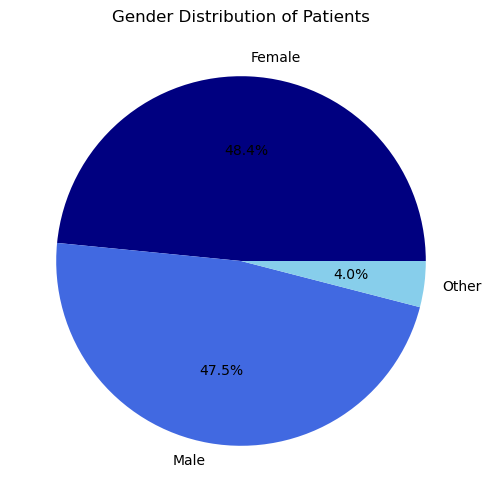

In [35]:
# Pie chart
gender_count.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6, 6),
    colors=["navy","royalblue","skyblue"],
    title="Gender Distribution of Patients"
)

plt.ylabel("")
plt.show()

The pie chart shows the percentage distribution of patients across the three gender categories: Female, Male, and Other. Female patients form the largest proportion, while Male patients have a very similar proportion. The Other category represents a smaller proportion of the patients.

### Insight

Female and male patients are almost equally represented in the dataset, while the proportion of patients in the Other category is comparatively lower.

### Benefit

This visualization helps the hospital understand the gender composition of its patient population and supports demographic analysis.

## 2. Age Distribution of Patients

### Analysis and Visualization

In this analysis, we use the `Age` column to understand the age distribution of patients. The `groupby()` method is used to group patients based on age and count the number of patients in each age group. The summarized result is then visualized using a histogram to understand how patient ages are distributed.

In [36]:
# GroupBy Method
age_count=df.groupby("Age")["Patient_ID"].count()
print(age_count)

Age
0       2
1      20
2      26
3      28
4      26
       ..
87     47
88     36
89     24
90     39
110     1
Name: Patient_ID, Length: 92, dtype: int64


The `groupby()` operation provides the number of patients for each age value. These summarized results help us understand how patients are distributed across different ages and will be used for the visualization.

Histogram chart

A histogram is used to visualize the age distribution of patients. It groups ages into intervals and shows how many patients fall within each age range.

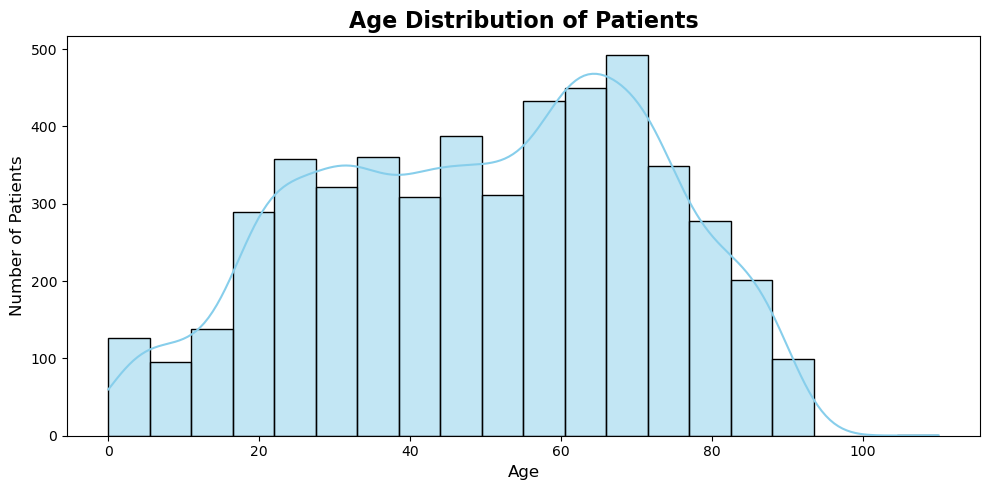

In [37]:
# Histogram chart 
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Age'],
    bins=20,
    kde=True,
    color= "skyblue",
    edgecolor='black'
)

plt.title('Age Distribution of Patients', fontsize=16, fontweight='bold')
plt.xlabel('Age', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.tight_layout()
plt.show()

The histogram shows how patients are distributed across different age ranges. The bars represent the number of patients within each age interval, while the curve shows the overall distribution pattern of patient ages.

### Insight

The hospital serves a large number of middle-aged and elderly patients. These age groups are generally associated with chronic diseases, longer treatment durations, and higher healthcare resource utilization. Understanding this age profile helps hospital management plan age-specific healthcare services and allocate resources more effectively.

### Benefit

The age distribution chart helps the hospital identify the most common patient age groups. This information can be used for better staffing, resource planning, specialized care services, and improving overall patient management.

## 3 .Monthly Patient Visits    

### Analysis and Visualization

In this analysis, we use the `Month` column to understand the number of patient visits across different months. The `groupby()` method is used to count the number of patients for each month. The summarized monthly data will then be visualized using a line chart to identify changes in patient visits over time.

In [38]:
#Groupby Method
monthly_visits=df.groupby("Month",observed=True)["Patient_ID"].count()
monthly_visits

Month
January      392
February     411
March        417
April        431
May          437
June         407
July         399
August       431
September    401
October      468
November     353
December     453
Name: Patient_ID, dtype: int64

The `groupby()` operation provides the total number of patient visits for each month. The monthly counts are arranged in chronological order from January to December. These summarized values will be used to create the line chart.

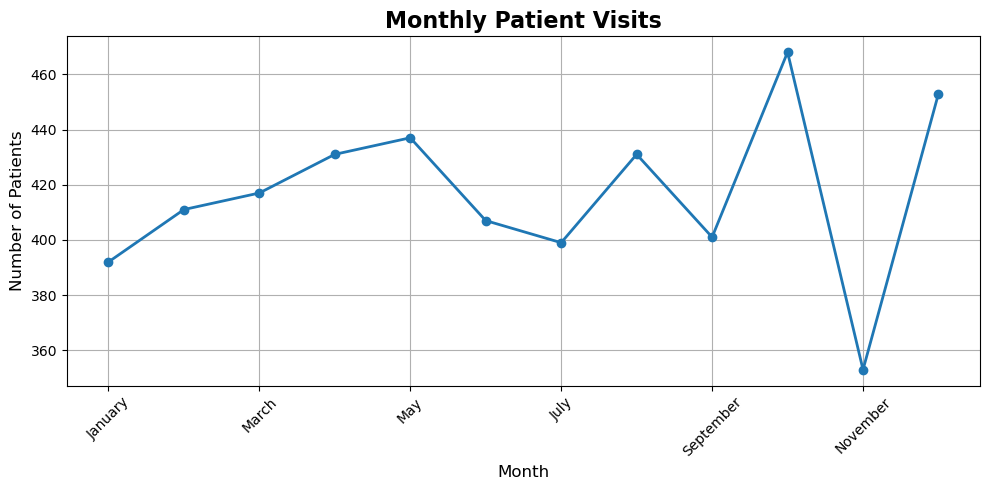

In [39]:
#Line chart
plt.figure(figsize=(10, 5))

monthly_visits.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Monthly Patient Visits", fontsize=16, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

The line chart shows the monthly trend in patient visits from January to December. The number of visits varies across the months, with October showing the highest number of patient visits and November showing the lowest.

### Insight

Patient visits reach their highest level in October and decrease to the lowest level in November. This indicates a noticeable change in patient demand between these two months.

### Benefit

This trend analysis helps the hospital identify periods of high and low patient demand, supporting better planning of beds, staff, and other healthcare resources.

## 4. Length of Stay by Severity

### Analysis and Visualization

In this analysis, we use the `Severity` and `Length_of_Stay` columns to understand how the length of hospital stay varies across different severity levels. The `groupby()` method is used to summarize the length of stay for each severity category. A box plot is used to compare the distribution, median, and variation of hospital stay across severity levels.

In [40]:
#GroupBy()
los_summary = df.groupby("Severity")["Length_of_Stay"].agg(
    ["count", "mean", "median", "min", "max"]
)
los_summary

,count,mean,median,min,max
Severity,,,,,
Critical,401,20.109726,20.0,1.0,90.0
Mild,1749,0.828473,0.0,0.0,120.0
Moderate,1792,3.252790,3.0,0.0,90.0
Severe,1058,9.560491,10.0,1.0,90.0


The `groupby()` operation provides the count, mean , median , minimum and maximum length of stay for each severity category.These summarized values help us compare hospital stay patterns across different severity levels.

#Box Plot

A box plot is used to compare the distribution of `Length of stay` across different `Severity` categories. It helps identify the median , spread , and possible outliers in the hospital stay foe each severity level.

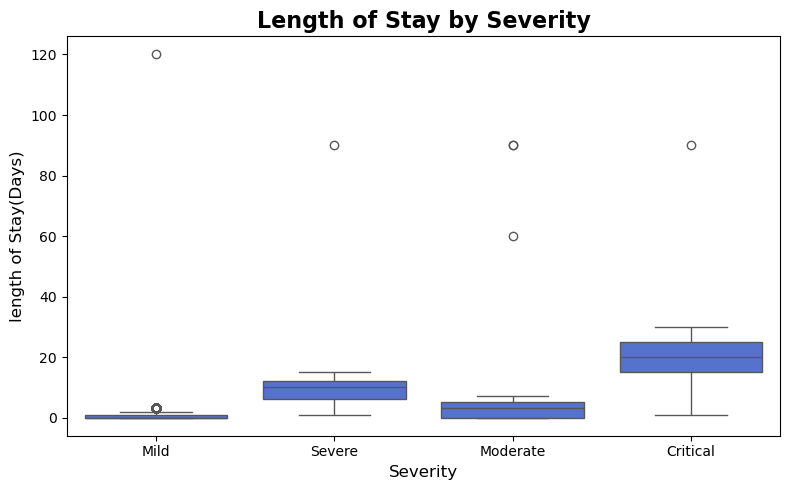

In [41]:
#Box Plot
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Severity",
    y="Length_of_Stay",
    color="royalblue")

plt.title("Length of Stay by Severity",fontsize=16,
          fontweight="bold")
plt.xlabel("Severity",fontsize=12)
plt.ylabel("length of Stay(Days)",fontsize=12)
plt.tight_layout()
plt.show()

### Insight

As sevcerity increases, the typical length of hospital stay also increase.Critical patients have the highest and most variable length of stay,while Mild patient generally have the shortest satys. However, extreme long_stay cases occur in every severity category and should be investigated separately.


### Benefit
This plot helps us understand the relationship between patient severity and hospital length of stay, while also identifying variations and unusually long stays.

## 5. Age vs Length of Stay

### Analysis and Visualization

In this analysis, we use the `Age` and `Length_of_Stay` columns to examine whether patient age is related to the duration of hospital stay. The `groupby()` method is used to summarize the length of stay for different age groups. A scatter plot is used to visualize the relationship between age and length of stay.

In [42]:
#GroupBy()
age_los_summary = df.groupby("Age")["Length_of_Stay"].agg(
    ["count", "mean", "median"]
)
age_los_summary

,count,mean,median
Age,,,
0,2,0.000000,0.0
1,20,2.450000,0.0
2,26,5.000000,3.5
3,28,6.607143,2.5
4,26,4.000000,2.5
...,...,...,...
87,47,5.446809,4.0
88,36,5.194444,3.0
89,24,1.583333,0.0


The `groupby()` operation provides the number of patients, average length of stay, and median length of stay for each age. These summarized values help us understand how hospital stay varies across different ages.

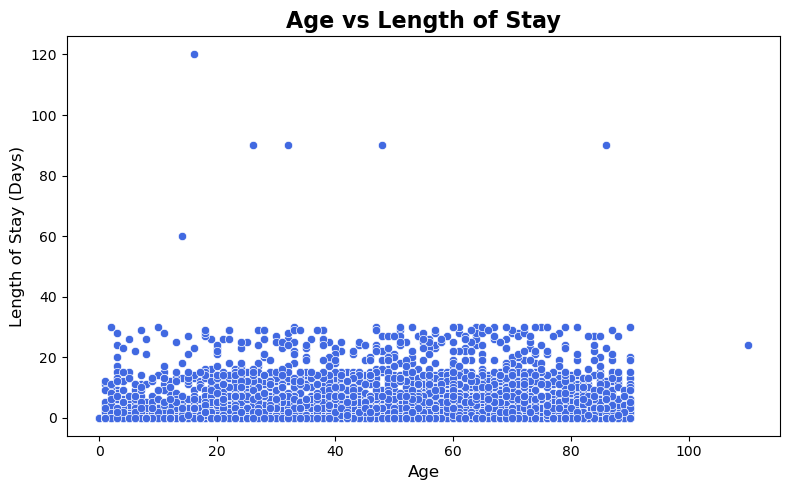

In [43]:
# Scatter Plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Length_of_Stay",
    color="royalblue"
)

plt.title("Age vs Length of Stay", fontsize=16, fontweight="bold")
plt.xlabel("Age", fontsize=12)
plt.ylabel("Length of Stay (Days)", fontsize=12)
plt.tight_layout()
plt.show()

The scatter plot shows the relationship between patient age and length of hospital stay. Each point represents one patient, allowing us to observe how the length of stay changes across different ages.

### Insight

The graph shows that most patients have a short hospital stay, regardless of age, with a few long-stay outliers. Therefore, age does not appear to have a strong relationship with length of stay.

### Benefit

This visualization helps the hospital understand whether patient age is associated with the duration of hospital stay. It supports better resource planning by showing that age alone may not be a strong factor in predicting length of stay.

## 6. Patient Distribution by Disease

### Analysis and Visualization

In this analysis, we use the `Disease` column to understand the number of patients affected by each disease. The `groupby()` method is used to count patients for each disease category. A bar chart is used to compare the patient count across different diseases.

In [44]:
#GroupBy()
disease_count = df.groupby("Disease")["Patient_ID"].count()
disease_count

Disease
Allergy                   291
Anemia                    216
Arthritis                 191
Asthma                    192
Bronchitis                277
COVID-19                  266
Chronic Kidney Disease    221
Dengue                    358
Diabetes                  226
Food Poisoning            364
Gastritis                 314
Heart Disease             183
Hypertension              189
Influenza                 359
Liver Disease             215
Migraine                  184
Pneumonia                 290
Stroke                    228
Thyroid Disorder          198
Tuberculosis              238
Name: Patient_ID, dtype: int64

The `groupby()` operation provides the total number of patients for each disease category. These summarized values help us compare the patient distribution across different diseases and will be used to create the bar chart.

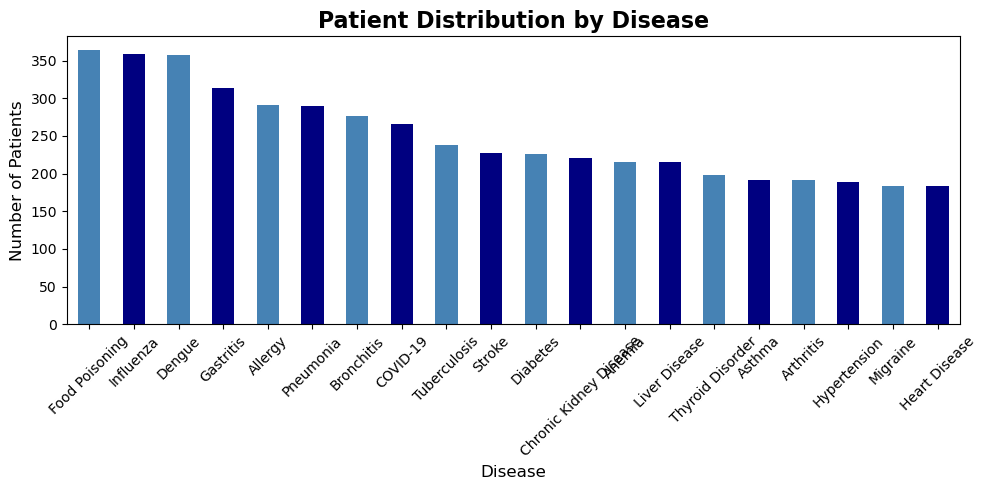

In [45]:
#Bar chart
plt.figure(figsize=(10, 5))

disease_count.sort_values(ascending=False).plot(
    kind="bar",
    color=["steelblue","navy"]
)

plt.title("Patient Distribution by Disease", fontsize=16, fontweight="bold")
plt.xlabel("Disease", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The patient distribution varies across diseases. Food Poisoning, Influenza, and Dengue have the highest patient counts, while Heart Disease, Migraine, Hypertension, and Arthritis have comparatively lower patient counts. This indicates that certain diseases contribute significantly more to the hospital's overall patient load.

### Insight

The graph helps identify the diseases that place the greatest demand on hospital services. High-volume diseases such as Food Poisoning, Influenza, and Dengue may require more doctors, nursing staff, medicines, diagnostic facilities, and hospital resources. Understanding disease patterns enables better planning and resource allocation.

### Benefit

This analysis helps hospital management:

• Identify the most common diseases treated in the hospital.
• Allocate doctors and nurses more efficiently.
• Plan medicine inventory based on disease demand.
• Prepare for seasonal disease outbreaks.
• Improve department-level resource planning.
• Support preventive healthcare and awareness programs.

## 7. Patient Distribution by Department

### Analysis and Visualization

In this analysis, we use the `Department` column to understand the number of patients handled by each hospital department. The `groupby()` method is used to count patients for each department. A horizontal bar chart is used to compare patient counts across departments clearly.

In [59]:
#GroupBy()
department_count = df.groupby("Department")["Patient_ID"].count()
department_count

Department
Cardiology           277
Gastroenterology     740
General Medicine    1482
ICU                  959
Nephrology           141
Neurology            286
Orthopedics          177
Pulmonology          863
Name: Patient_ID, dtype: int64

The `groupby()` operation provides the total number of patients for each department. These summarized values help us compare patient distribution across different hospital departments.

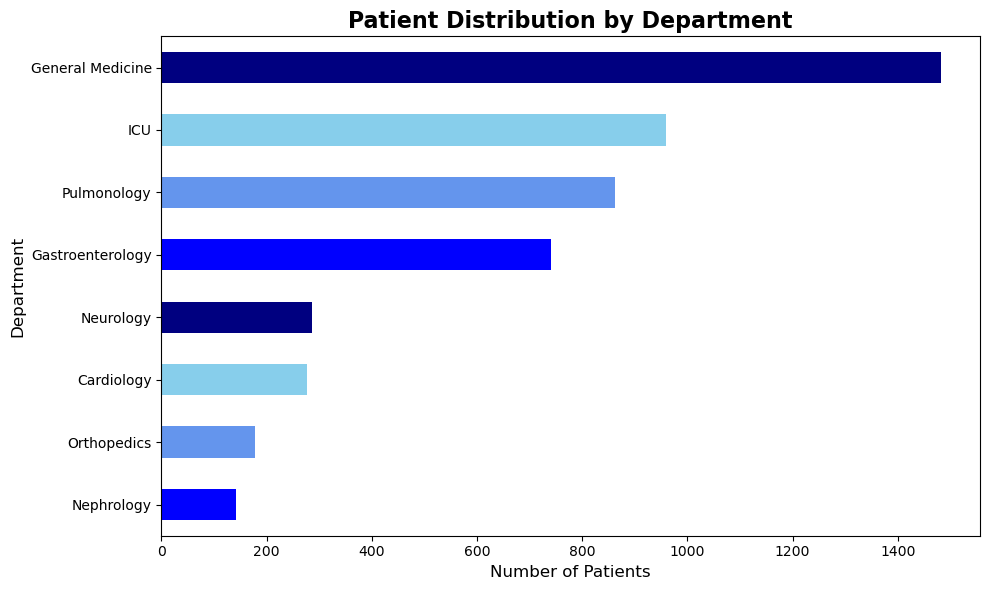

In [65]:
#Horizontal Bar chart
plt.figure(figsize=(10, 6))

department_count.sort_values().plot(
    kind="barh",
    color=["blue","cornflowerblue","skyblue","navy"]
)

plt.title("Patient Distribution by Department", fontsize=16, fontweight="bold")
plt.xlabel("Number of Patients", fontsize=12)
plt.ylabel("Department", fontsize=12)
plt.tight_layout()
plt.show()

The General Medicine department has the highest number of patients, followed by ICU, Pulmonology, and Gastroenterology. Neurology, Cardiology, and Orthopedics have comparatively lower patient volumes. This indicates that patient demand is concentrated in a few key departments.

### Insight
The analysis shows that General Medicine and ICU handle a significant portion of the hospital workload. These departments are likely to require more doctors, nurses, beds, medical equipment, and operational support compared to lower-volume departments.

### Benefit

This visualization helps hospital management:

• Identify high-demand departments.
• Allocate staff more efficiently.
• Plan bed and equipment requirements.
• Optimize department-level resource utilization.
• Reduce patient waiting times through better workforce planning.
• Support future budgeting and infrastructure decisions.

## 8. Patient Visits by Season

### Analysis and Visualization

In this analysis, we use the `Season` column to understand the number of patient visits across different seasons. The `groupby()` method is used to count patients for each season. An area chart is used to visualize the variation in patient visits across seasons.

In [77]:
#GroupBy()
season_count = df.groupby("Season")["Patient_ID"].count()
season_count

Season
Autumn      823
Monsoon    1231
Spring      846
Summer      846
Winter     1254
Name: Patient_ID, dtype: int64

The `groupby()` operation provides the total number of patient visits for each season. These summarized values will be used to create the area chart.

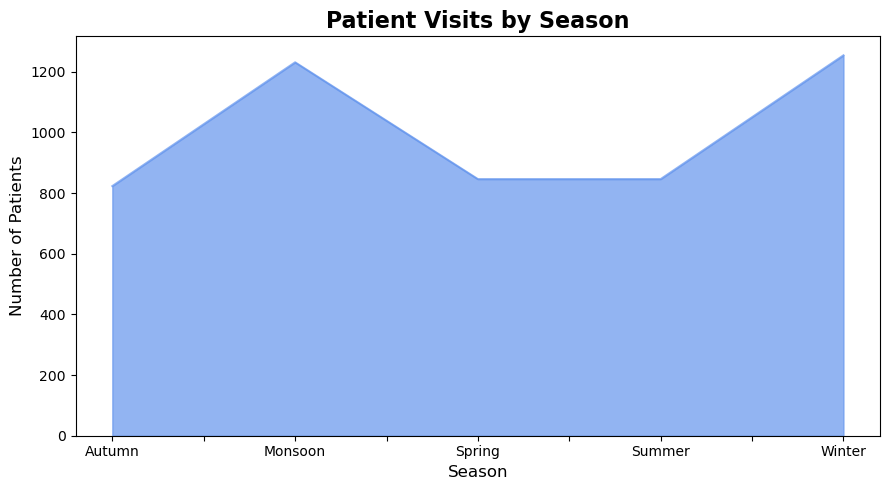

In [78]:
#Area chart
plt.figure(figsize=(9, 5))

season_count.plot(
    kind="area",
    color="cornflowerblue",
    alpha=0.7
)

plt.title("Patient Visits by Season", fontsize=16, fontweight="bold")
plt.xlabel("Season", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)
plt.tight_layout()
plt.show()

Patient visits vary across different seasons. The highest number of patient visits occurs during the Monsoon and Winter seasons, while Spring and Summer show comparatively lower patient volumes. This indicates a seasonal pattern in hospital demand.

### Insight

The hospital experiences increased patient inflow during Monsoon and Winter. Seasonal diseases such as respiratory infections, influenza, dengue, and other weather-related illnesses may contribute to this rise. Understanding seasonal trends helps management prepare resources in advance.

### Benefit

This analysis helps hospital management anticipate seasonal patient demand and plan staff, beds, and medical resources more effectively.

## 9. Beds Available vs Occupied

### Analysis and Visualization

In this analysis, we use the `Total_Beds_Available` and `Beds_Occupied` columns to understand hospital bed utilization. The `groupby()` method is used to summarize the total available and occupied beds. A grouped bar chart is used to compare the two measures.

In [80]:
#GroupBy()
bed_summary = df.groupby("Department")[[
    "Total_Beds_Available",
    "Beds_Occupied"
]].mean()
bed_summary

,Total_Beds_Available,Beds_Occupied
Department,,
Cardiology,160.126354,103.317690
Gastroenterology,167.117568,107.705405
General Medicine,164.387989,110.612686
ICU,164.952033,110.168926
Nephrology,171.014184,110.702128
Neurology,168.293706,109.230769
Orthopedics,159.790960,104.677966
Pulmonology,163.388181,109.231750


The `groupby()` operation provides the average number of available beds and occupied beds for each department. These summarized values help us compare bed availability and utilization across departments.

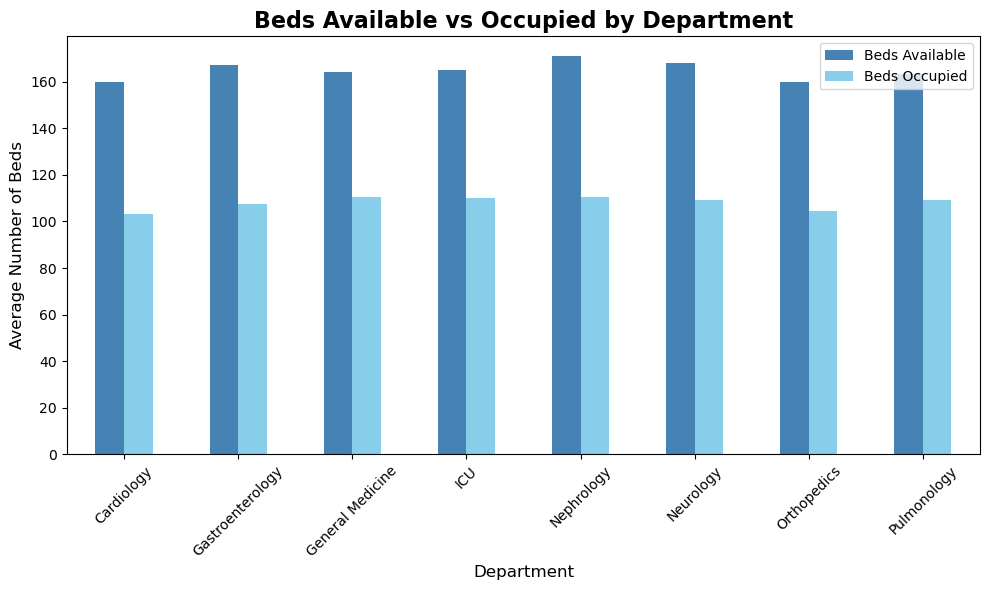

In [81]:
#Bar chart
ax = bed_summary.plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "skyblue"]
)

plt.title("Beds Available vs Occupied by Department", fontsize=16, fontweight="bold")
plt.xlabel("Department", fontsize=12)
plt.ylabel("Average Number of Beds", fontsize=12)
plt.xticks(rotation=45)
plt.legend(["Beds Available", "Beds Occupied"])
plt.tight_layout()
plt.show()

Across all departments, the number of occupied beds is consistently lower than the number of available beds. Bed occupancy appears relatively balanced, with no department showing complete utilization of its available capacity.

### Insight

The hospital maintains sufficient bed capacity across departments, reducing the risk of bed shortages during normal operations. However, some departments may have unused capacity that could be optimized.

### Benefit

The analysis shows that the hospital has reserve bed capacity across departments, helping management accommodate sudden increases in patient admissions while maintaining efficient resource utilization.

## 10. Severity by Admission Type

#### Analysis and Visualization

In this analysis, we use the `Severity` and `Admission_Type` columns to understand how patients with different severity levels are distributed across admission types. The `groupby()` method is used to count patients for each combination of severity and admission type. A stacked bar chart is used to compare these categories.

In [85]:
#GroupBy()
severity_admission = df.groupby(
    ["Admission_Type", "Severity"]
)["Patient_ID"].count().unstack(fill_value=0)

severity_admission

Severity,Critical,Mild,Moderate,Severe
Admission_Type,,,,
Emergency,284,206,432,471
Inpatient,112,438,820,542
OPD,5,1105,540,45


The `groupby()` operation provides the number of patients for each combination of admission type and severity level. These summarized values help us compare patient severity across different admission types.

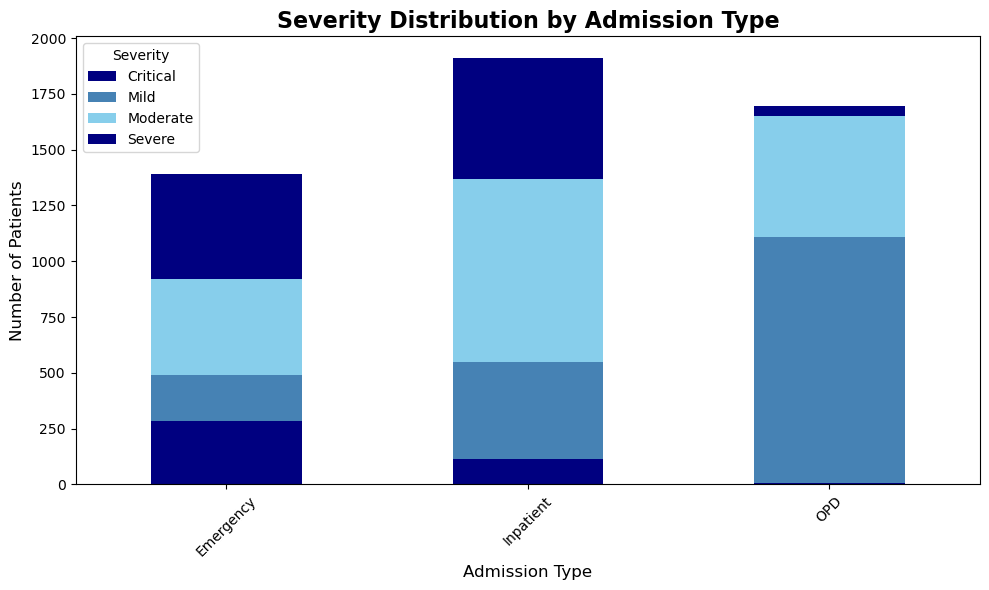

In [89]:
# Bar chart
severity_admission.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["navy", "steelblue", "skyblue"]
)

plt.title(
    "Severity Distribution by Admission Type",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Admission Type", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Severity")
plt.tight_layout()
plt.show()

The stacked bar chart shows the number of patients at each severity level within different admission types. It allows us to compare both the total patient count and the severity composition.

### Insight
Inpatient has the highest number of patients and a higher share of severe/critical cases.
Emergency has a mix of all severity levels, showing the need for quick treatment and proper resource allocation.
OPD has mostly mild and moderate patients, with very few severe/critical cases.

### Benefit
Helps the hospital understand patient severity by admission type.Supports better staff and bed allocation, especially for inpatient and emergency departments.Helps management plan resources and prioritize critical patients.

## 11. Patient Distribution by Department and Severity

### Analysis and Visualization

In this analysis, we use the `Department` and `Severity` columns to understand how patients with different severity levels are distributed across hospital departments. The `groupby()` method is used to count patients for each combination of department and severity. A heatmap is used to visualize the patient counts using different shades of blue.

In [90]:
#GroupBy()
department_severity = df.groupby(
    ["Department", "Severity"]
)["Patient_ID"].count().unstack(fill_value=0)
department_severity

Severity,Critical,Mild,Moderate,Severe
Department,,,,
Cardiology,6,108,121,42
Gastroenterology,7,374,292,67
General Medicine,7,701,621,153
ICU,338,0,80,541
Nephrology,6,35,75,25
Neurology,9,112,118,47
Orthopedics,2,101,58,16
Pulmonology,22,295,397,149


The `groupby()` operation provides the number of patients for each combination of department and severity level. The `unstack()` method converts the severity categories into columns, while `fill_value=0` replaces missing combinations with zero.

### Visualization Heatmap

A heatmap is used to visualize the patient distribution across departments and severity levels. Darker blue shades represent higher patient counts, while lighter blue shades represent lower patient counts.

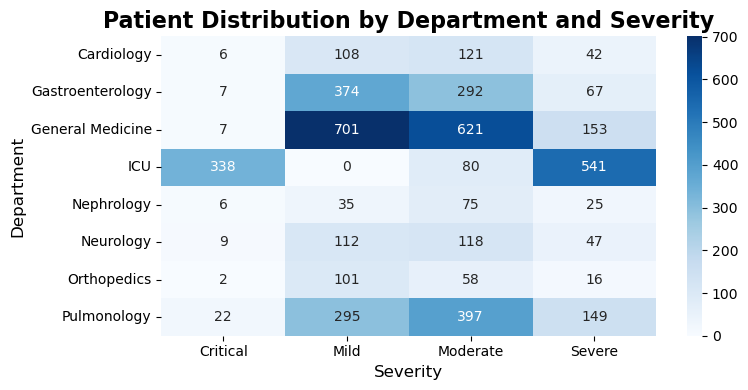

In [93]:
plt.figure(figsize=(8, 4))

sns.heatmap(
    department_severity,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Patient Distribution by Department and Severity",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Severity", fontsize=12)
plt.ylabel("Department", fontsize=12)

plt.tight_layout()
plt.show()

Observation: The patient distribution varies across departments. General Medicine has the highest overall patient load, while ICU has the highest number of severe cases.

### Insight
General Medicine has the highest number of mild and moderate patients, while ICU has the highest number of severe patients.

### Benefit
This analysis helps the hospital identify high-demand and critical departments and allocate staff, beds, and resources effectively.

## 12. Oxygen Usage by Severity

### Analysis and Visualization

In this analysis, we use the `Severity` and `Oxygen_Units_Used` columns to understand how oxygen usage varies across different severity levels. The `groupby()` method is used to summarize oxygen usage for each severity category. A box plot is used to compare the distribution and variation of oxygen usage across severity levels.

In [46]:
#GroupBy()
oxygen_severity = df.groupby("Severity")["Oxygen_Units_Used"].agg(
    ["count", "mean", "median", "min", "max"]
)
oxygen_severity

,count,mean,median,min,max
Severity,,,,,
Critical,401,198.159601,230.0,0.0,390.0
Mild,1749,4.287593,3.0,0.0,800.0
Moderate,1792,15.029018,4.0,0.0,500.0
Severe,1058,72.176749,83.0,0.0,800.0


The `groupby()` operation provides the count, mean, median, minimum, and maximum oxygen usage for each severity category. These values help us compare oxygen requirements across different severity levels.

Box plot

A box plot is used to compare the distribution of `Oxygen_Units_Used` across severity levels. It shows the median, variation, and possible outliers in oxygen usage.

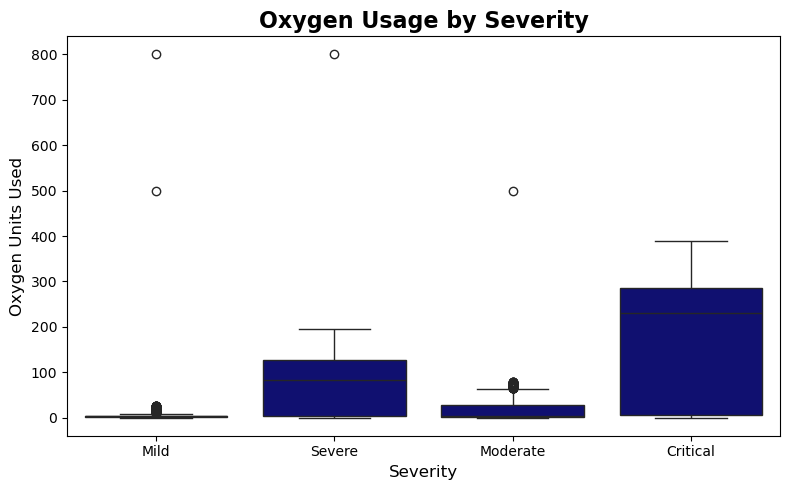

In [50]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Severity",
    y="Oxygen_Units_Used",
    color="navy"
)

plt.title(
    "Oxygen Usage by Severity",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Severity", fontsize=12)
plt.ylabel("Oxygen Units Used", fontsize=12)

plt.tight_layout()
plt.show()

 Observation
 
 Critical patients have the highest oxygen usage compared with other severity levels.Severe patients show higher oxygen usage than Moderate and Mild patients.Mild patients generally have the lowest oxygen requirements.Oxygen usage varies more widely among Critical and Severe patients.several outliers indicate unusually high oxygen usage in some patients.Overall, oxygen usage appears to increase with the severity of the patient's condition.

### Insight
Oxygen usage generally increases as the severity of the patient's condition increases. Critical patients have the highest median oxygen usage and the greatest variability, while Mild and Moderate patients generally require less oxygen. Some extreme outliers are also visible.

### Benefit
This analysis helps hospitals understand oxygen requirements by severity level, plan oxygen resources efficiently, identify unusual cases, and support better clinical and operational decision-making.

## 13. Monthly Oxygen Units Used 

### Analysis and Visualization

In this analysis, we use the `Month` and `Oxygen_Units_Used` columns to understand how oxygen usage changes across different months. The `groupby()` method is used to calculate the total oxygen units used each month. A line chart is used to show the monthly trend.

In [52]:
#GroupBY()
monthly_oxygen = df.groupby("Month")["Oxygen_Units_Used"].sum()
monthly_oxygen

C:\Users\umair\AppData\Local\Temp\ipykernel_6552\1719696103.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_oxygen = df.groupby("Month")["Oxygen_Units_Used"].sum()


Month
January      18551.0
February     22113.0
March        14967.0
April        17491.0
May          12754.0
June         13415.0
July         12212.0
August       13158.0
September    13638.0
October      18023.0
November     11356.0
December     22578.0
Name: Oxygen_Units_Used, dtype: float64

The `groupby()` operation provides the total oxygen units used in each month. These values help us identify monthly changes in oxygen demand.

 Line Chart Visualization 

A line chart is used to show the monthly trend in oxygen usage. It helps us observe how oxygen demand increases or decreases throughout the year.

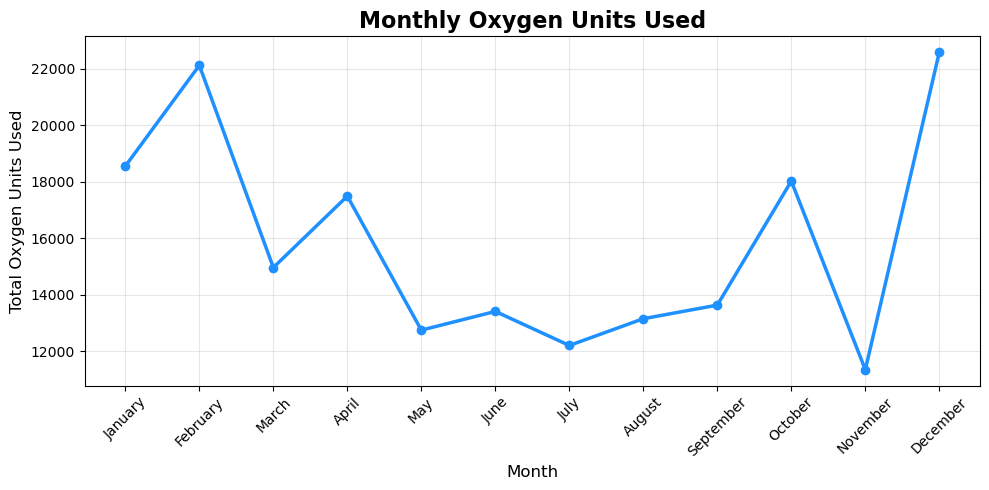

In [53]:
#Line chart
plt.figure(figsize=(10,5))

plt.plot(
    monthly_oxygen.index,
    monthly_oxygen.values,
    marker="o",
    linewidth=2.5,
    color="dodgerblue"
)

plt.title("Monthly Oxygen Units Used", fontsize=16, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Oxygen Units Used", fontsize=12)
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Observation

The chart shows that monthly oxygen usage fluctuates significantly throughout the year, with the highest usage in February and December at around 22,000 units and the lowest in November at around 11,500 units. Overall, oxygen demand varies considerably from month to month.

### Insight
The monthly trend indicates that oxygen demand is not constant and varies considerably across the year. The highest demand occurs in February and December, while the lowest demand occurs in November. The repeated peaks suggest that certain periods may experience increased patient admissions or higher oxygen requirements.

### Benefit
The analysis helps hospitals forecast oxygen demand, plan oxygen supplies efficiently, and prepare for high-demand months, reducing the risk of shortages and supporting better resource management.

## 14. ICU Beds Available vs Occupied

### Analysis and Visualization

In this analysis, we use the `ICU_Beds_Available` and `ICU_Beds_Occupied` columns to understand ICU bed utilization across hospital departments. The `groupby()` method is used to calculate the average available and occupied ICU beds for each department. A grouped bar chart is used to compare ICU bed availability and occupancy.

In [56]:
#GroupBy()
icu_bed_summary = df.groupby("Department")[[
    "ICU_Beds_Available",
    "ICU_Beds_Occupied"
]].mean()
icu_bed_summary

,ICU_Beds_Available,ICU_Beds_Occupied
Department,,
Cardiology,23.700361,12.610108
Gastroenterology,24.301351,12.736486
General Medicine,23.476383,12.312416
ICU,23.666319,12.424400
Nephrology,24.531915,13.418440
Neurology,24.367133,12.615385
Orthopedics,25.327684,13.508475
Pulmonology,23.813441,12.643105
Unknown,22.440000,11.893333


The `groupby()` operation provides the average number of available and occupied ICU beds for each department. These values help us compare ICU bed availability and utilization across departments.

Bar chart Visualization 

A grouped bar chart is used to compare available and occupied ICU beds across departments. Two different blue shades are used to make the comparison clear.

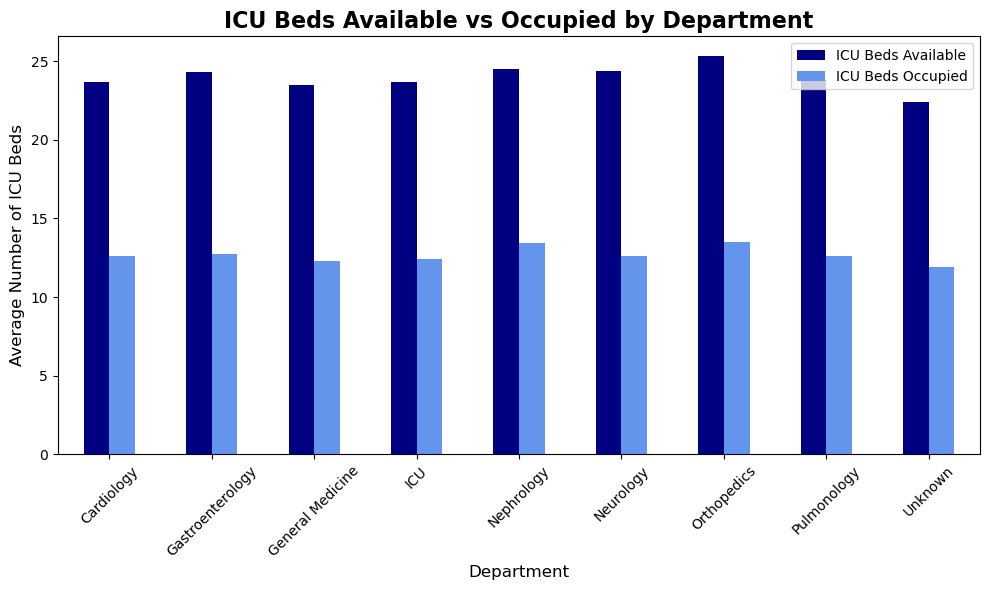

In [62]:
#Bar Chart
ax = icu_bed_summary.plot(
    kind="bar",
    figsize=(10, 6),
    color=["navy", "cornflowerblue"]
)

plt.title(
    "ICU Beds Available vs Occupied by Department",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Department", fontsize=12)
plt.ylabel("Average Number of ICU Beds", fontsize=12)

plt.xticks(rotation=45)
plt.legend(["ICU Beds Available", "ICU Beds Occupied"])

plt.tight_layout()
plt.show()

Observation

The chart shows that ICU beds occupied are consistently lower than the beds available across all departments. Orthopedics has the highest ICU bed availability and occupancy, while the Unknown department has the lowest. Overall, there is a considerable gap between available and occupied beds.

### Insight
ICU capacity appears to be sufficient across departments, with many beds remaining available. Orthopedics shows relatively higher ICU demand compared with other departments.

### Benefit
This analysis helps hospitals monitor ICU utilization, identify departments with higher demand, and plan bed allocation effectively to ensure better use of available ICU resources.

## 15. Length of Stay Distribution

### Analysis and Visualization

In this analysis, we use the `Length_of_Stay` column to understand how long patients stay in the hospital. The `groupby()` method is used to summarize the number of patients for each length of stay. A histogram is used to visualize the distribution of hospital stay duration.

In [63]:
#GroupBy()
stay_count = df.groupby("Length_of_Stay")["Patient_ID"].count()
stay_count

Length_of_Stay
0.0      1624
1.0       241
2.0       425
3.0       510
4.0       184
5.0       322
6.0       298
7.0       279
8.0        84
9.0        90
10.0      108
11.0      112
12.0      119
13.0      102
14.0      114
15.0      100
16.0       17
17.0       15
18.0       15
19.0       27
20.0       12
21.0       18
22.0       18
23.0       19
24.0       20
25.0       24
26.0       19
27.0       21
28.0       13
29.0       21
30.0       23
60.0        1
90.0        4
120.0       1
Name: Patient_ID, dtype: int64

The `groupby()` operation provides the number of patients for each length of stay. These summarized values help us understand how frequently different hospital stay durations occur.

Histogram plot Visualization

A histogram is used to visualize the distribution of `Length_of_Stay`. It helps us identify the most common stay durations and observe the overall spread of hospital stays.

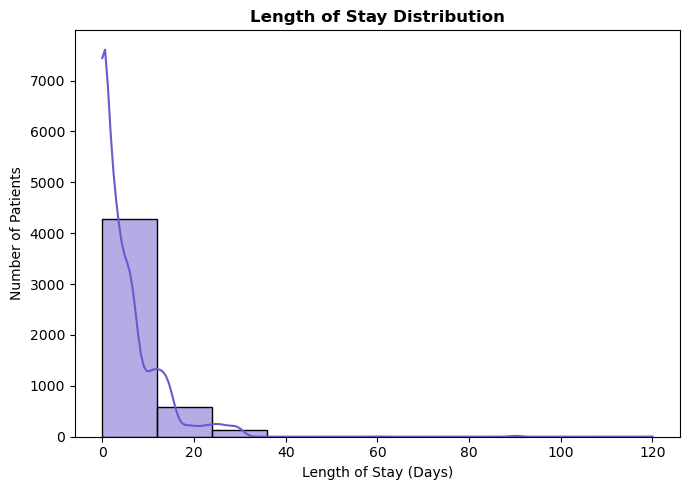

In [75]:
plt.figure(figsize=(7, 5))

sns.histplot(
    df["Length_of_Stay"],
    bins=10,
    kde=True,
    color="slateblue"
)

plt.title(
    "Length of Stay Distribution",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("Length of Stay (Days)", fontsize=10)
plt.ylabel("Number of Patients", fontsize=10)

plt.tight_layout()
plt.show()

Observation

The distribution is highly right-skewed, with most patients having a short length of stay, mainly within the first 10–15 days. The number of patients decreases sharply as the length of stay increases, with only a small number of patients staying for more than 20 days.

### Insight
Most hospital patients have relatively short stays, while long-term stays are less common. This indicates that a small group of patients may require extended care and hospital resources.

### Benefit
This analysis helps hospitals plan bed capacity, staffing, and resources more effectively while identifying the demand for long-term patient care.

## 16. Readmission Status

### Analysis and Visualization

In this analysis, we use the `Readmission_Within_30_Days` column to understand the number of patients who were readmitted within 30 days and those who were not. The `groupby()` method is used to count patients in each readmission category. A pie chart is used to show the proportion of each category.

In [65]:
#GroupBy()
readmission_count = df.groupby(
    "Readmission_Within_30_Days"
)["Patient_ID"].count()
readmission_count

Readmission_Within_30_Days
No     4309
Yes     691
Name: Patient_ID, dtype: int64

The `groupby()` operation provides the total number of patients in each readmission category. These values help us compare patients who were readmitted within 30 days with those who were not.

Pie chart

A pie chart is used to show the proportion of patients based on their readmission status. Each slice represents a readmission category, and its size represents the proportion of patients in that category.

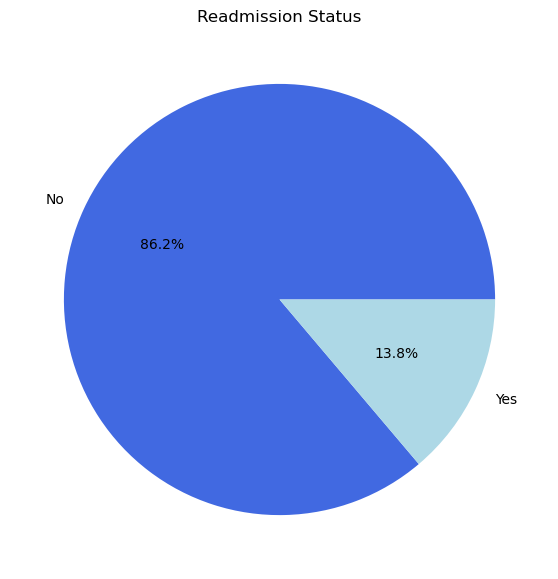

In [71]:
readmission_count.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    colors=["royalblue", "lightblue"],
    title="Readmission Status"
)

plt.ylabel("")
plt.show()

 Observation

The pie chart shows that **86.2% of patients were not readmitted**, while only **13.8% were readmitted**. This indicates that the majority of patients did not require hospital readmission.

### Insight
The low readmission rate suggests that most patients received effective treatment and were discharged without requiring further hospitalization.

### Benefit
This analysis helps hospitals monitor readmission rates, evaluate the effectiveness of patient care, and identify opportunities to improve discharge planning and follow-up care.

# Overall Project Insights

The Hospital Operations Analysis provides an overall understanding of patient visits, disease distribution, severity levels, length of stay, bed utilization, oxygen usage, and hospital resource requirements.

The analysis shows that patient demand varies across months, departments, diseases, and severity levels. Length of stay and oxygen requirements also vary among patients. The analysis helps identify areas where hospital resources need better planning and management.

# Key Findings

- Female and male patients have almost similar representation in the dataset.
- Patient visits vary across different months, with October showing the highest patient visits and November showing the lowest.
- Patient volume varies across different diseases and hospital departments.
- Length of stay varies across different severity levels.
- Most patients have a relatively short hospital stay, with a few long-stay outliers.
- Oxygen usage varies across different severity levels.
- Bed availability and bed occupancy vary across departments.
- Patient severity distribution differs across admission types.
- The analysis shows variations in hospital resource requirements across different patient groups.
- Readmission patterns within 30 days provide useful information for understanding patient follow-up needs.

## Conclusion

The Hospital Operations Analysis provides a clear understanding of patient demand and hospital resource utilization. The analysis of patient visits, diseases, departments, severity levels, length of stay, bed occupancy, ICU utilization, oxygen usage, and readmission patterns reveals important operational trends.

The visualizations and `groupby()` analysis help identify variations in patient demand and resource requirements. These findings can support hospital management in improving resource allocation, capacity planning, and operational decision-making.

Overall, this project demonstrates how data analysis and visualization can be used to support better hospital operations and more effective healthcare resource management.

# Recommendations

- Monitor patient visits regularly to prepare for periods of high demand.
- Allocate beds according to department-level patient demand.
- Monitor ICU bed availability and occupancy to avoid capacity problems.
- Maintain sufficient oxygen resources based on patient requirements.
- Give additional attention to patients with higher severity levels.
- Monitor long-stay patients to improve bed availability.
- Use monthly and seasonal patient trends for staff and resource planning.
- Continue using data visualization and analysis for regular hospital performance monitoring.

# Final Visualization Check

The project includes a variety of visualizations to provide different perspectives of the hospital data.

### Visualizations Completed

1. Pie Chart – Gender Distribution
2. Histogram – Age Distribution
3. Line Chart – Monthly Patient Visits
4. Box Plot – Length of Stay by Severity
5. Scatter Plot – Age vs Length of Stay
6. Bar Chart – Patient Distribution by Disease
7. Horizontal Bar Chart – Patient Distribution by Department
8. Area Chart – Patient Visits by Season
9. Grouped Bar Chart – Beds Available vs Occupied
10. Stacked Bar Chart – Severity by Admission Type
11. Heatmap – Department and Severity
12. Box Plot – Oxygen Usage by Severity
13. Line chart - Monthly Oxygen Units Used
14. Grouped Bar Chart - ICU Beds Available vs Occupied
15. Histogram - Length of Stay Distribution
16. Pie Chart - Readmission Status

### Final Check

The visualizations use different chart types and are connected to the hospital operations problem. The `groupby()` method is used to summarize data before creating the visualizations. The graphs cover patient demographics, patient demand, disease, severity, length of stay, bed utilization, and oxygen requirementsand readmission patterns.